In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from google.colab import drive
drive.mount('/content/drive')
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import tensorflow.keras.backend as K
from tensorflow.keras.losses import binary_crossentropy

Mounted at /content/drive


In [ ]:
# Načítanie datasetov
file_paths = [
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Wednesday-workingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Tuesday-WorkingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
]

In [ ]:
# Definované features
selected_features = [
    'Average Packet Size', 'Max Packet Length', 'Avg Bwd Segment Size',
    'Bwd Packet Length Max', 'Packet Length Mean',
    'Bwd Packet Length Std', 'Packet Length Variance',
    'Avg Fwd Segment Size', 'Bwd Packet Length Mean', 'Packet Length Std',
    'Subflow Fwd Bytes', 'Fwd Packet Length Max',
    'Fwd Packet Length Min', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets'
]

In [ ]:
flow_features = [
    'Destination Port', 'Flow Duration',
    'Total Fwd Packets', 'Total Backward Packets',
    'Fwd Header Length', 'Bwd Header Length'
]

In [ ]:
# Načítanie a tvorba Flow_ID
dataframes = []
for file in file_paths:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    if df['Label'].dtype == object:
        df['Label'] = df['Label'].apply(lambda x: 0 if isinstance(x, str) and "BENIGN" in x.upper() else 1)
    else:
        df['Label'] = df['Label'].apply(lambda x: 0 if x == 0 else 1)
    dataframes.append(df)

df = pd.concat(dataframes, ignore_index=True)
df['Flow_ID'] = df[flow_features].astype(str).agg('-'.join, axis=1)

In [ ]:
# 2. --- Rozdelenie dát cez GroupShuffleSplit ---
gss = GroupShuffleSplit(test_size=0.3, n_splits=1, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df['Flow_ID']))
train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

In [ ]:
X_train = train_df[selected_features].replace([np.inf, -np.inf], np.nan).fillna(0)
X_test = test_df[selected_features].replace([np.inf, -np.inf], np.nan).fillna(0)
y_train = train_df['Label']
y_test = test_df['Label']

In [ ]:
# 3. --- Škálovanie dát pre NN ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Získaš unikátne triedy a ich váhy
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Prevedieš na slovník
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Vypíšeš, čo použiješ
print("Použité váhy tried:", class_weight_dict)

Použité váhy tried: {np.int64(0): np.float64(0.6655031537108924), np.int64(1): np.float64(2.0105452336981444)}


In [ ]:
def focal_loss(gamma=2., alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        BCE = binary_crossentropy(y_true, y_pred)
        pt = K.exp(-BCE)
        return alpha * (1 - pt) ** gamma * BCE
    return focal_loss_fixed

In [ ]:
# 4. --- Definovanie a trénovanie NN modelu ---
model = models.Sequential([
    layers.Dense(256, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])


optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss=focal_loss(gamma=2., alpha=0.25), metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    epochs=30, batch_size=512,
    validation_split=0.1,
    verbose=1,
    class_weight = {0: 1.0, 1: 2.0},
    callbacks=[early_stop]
)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.7833 - loss: 0.0333 - val_accuracy: 0.8803 - val_loss: 0.0123
Epoch 2/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8104 - loss: 0.0238 - val_accuracy: 0.7544 - val_loss: 0.0153
Epoch 3/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8178 - loss: 0.0227 - val_accuracy: 0.8771 - val_loss: 0.0113
Epoch 4/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8571 - loss: 0.0201 - val_accuracy: 0.9198 - val_loss: 0.0106
Epoch 5/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8843 - loss: 0.0179 - val_accuracy: 0.9805 - val_loss: 0.0077
Epoch 6/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8955 - loss: 0.0168 - val_accuracy: 0.9807 - val_loss: 0.0085
Epoch 7/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9009 - loss: 0.0159 - val_accuracy: 0.9838 - val_loss: 0.0071
Epoch 8/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9042 - loss: 0.0153 -

In [ ]:
# 5. --- Vyhodnotenie ---
y_pred_probs = model.predict(X_test_scaled)
y_pred = (y_pred_probs > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# SKúšam nový threshold
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_custom = (y_pred_probs > threshold).astype(int)
    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_test, y_pred_custom))
    print("Recall:", recall_score(y_test, y_pred_custom))
    print("F1-score:", f1_score(y_test, y_pred_custom))

21210/21210 ━━━━━━━━━━━━━━━━━━━━ 27s 1ms/step
Accuracy: 0.9607
Precision: 0.9103
Recall: 0.9173
F1-score: 0.9138

Threshold: 0.3
Precision: 0.6003602083113575
Recall: 0.9962980011799716
F1-score: 0.7492369650222815

Threshold: 0.4
Precision: 0.6445934829687578
Recall: 0.9957533989017188
F1-score: 0.7825858770117373

Threshold: 0.5
Precision: 0.9103491319958305
Recall: 0.9172723205892078
F1-score: 0.9137976134730588

Threshold: 0.6
Precision: 0.9710316064519371
Recall: 0.7517261947212479
F1-score: 0.8474202165563665


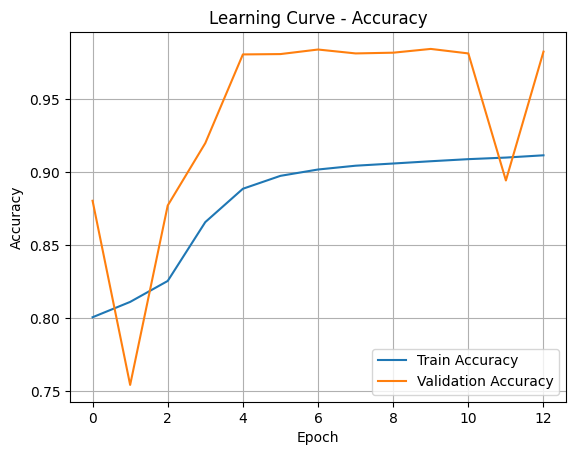

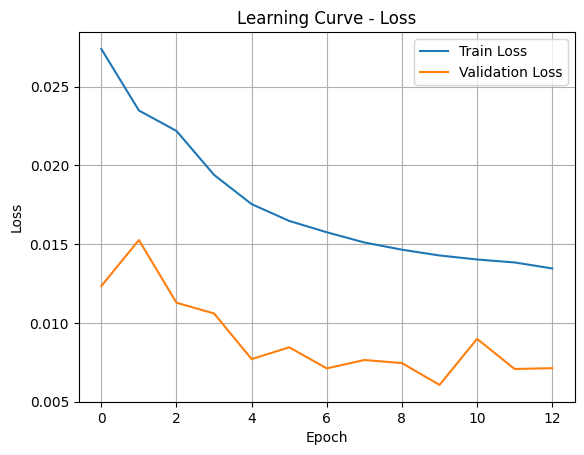

In [ ]:
# --- 6. Learning curve ---
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Learning Curve - Loss')
plt.legend()
plt.grid(True)
plt.show()


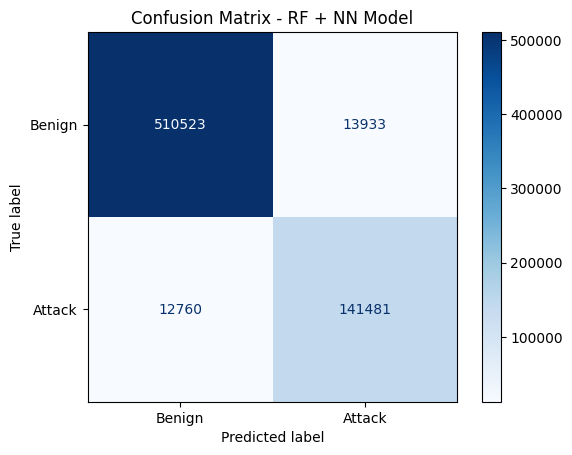

In [ ]:
# --- 7. Confusion matrix ---
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Attack'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - RF + NN Model')
plt.grid(False)
plt.show()

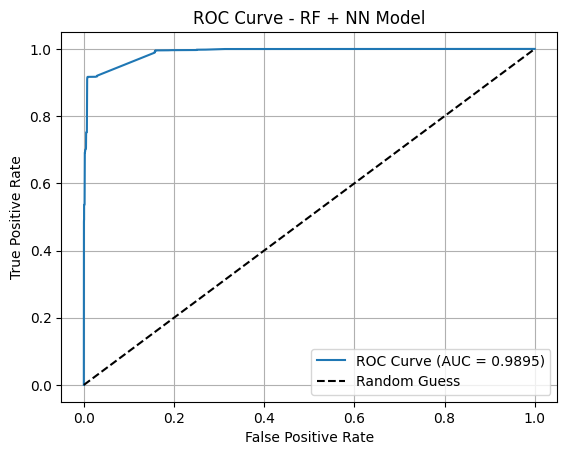

In [ ]:
# --- 8. ROC AUC curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - RF + NN Model')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()